<a href="https://colab.research.google.com/github/nevita275/PCVK26_20_Triya/blob/main/Week7_20_Triya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20

# PRAKTIKUM WEEK 7

## 1 dan 2 Import Library

In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

## 3. Global Threshold manual (thresh = 200)

In [58]:
filename = '/content/drive/MyDrive/PVCK/Images/gradient.jpg'
gradient = cv.imread(filename)

if gradient is None:
    print("Citra gradient tidak ditemukan!")
else:
    print("Citra gradient berhasil dibaca")
    print("Ukuran citra :", gradient.shape)

Citra gradient berhasil dibaca
Ukuran citra : (540, 960, 3)


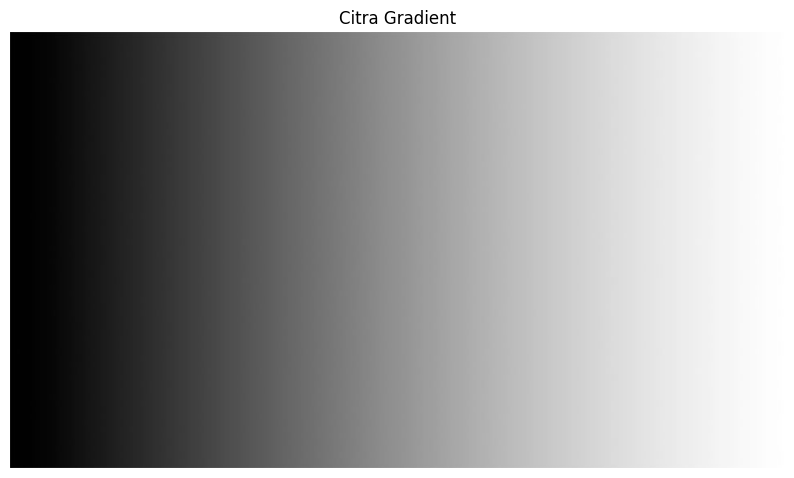

In [59]:
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(gradient, cv.COLOR_BGR2RGB))
plt.title('Citra Gradient')
plt.axis('off')
plt.show()

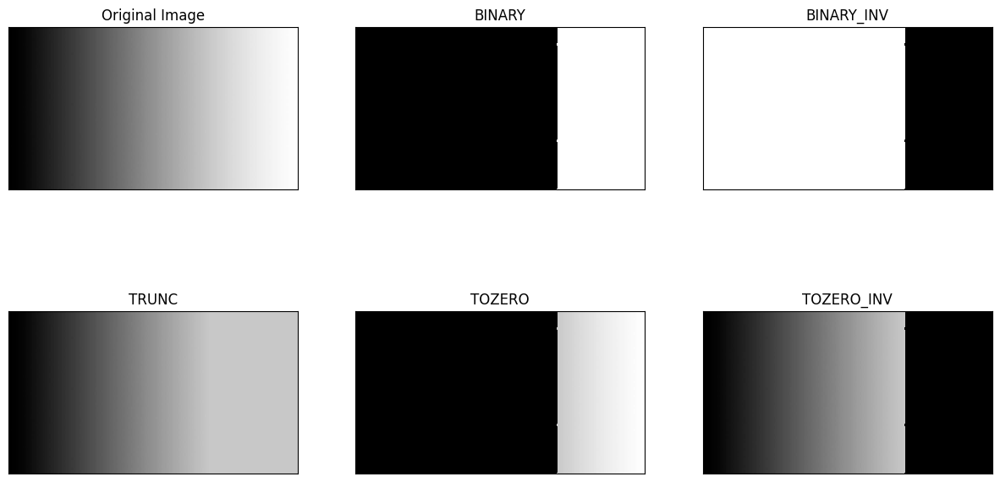

BINARY sama dengan OpenCV: True


In [60]:
img = cv.cvtColor(gradient, cv.COLOR_BGR2GRAY)   # grayscale 1 channel
thresh, maxval = 200, 255

# BINARY     : > thresh -> maxval, selain itu 0
binary     = np.where(img > thresh, maxval, 0).astype(np.uint8)
# BINARY_INV : > thresh -> 0, selain itu maxval
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
# TRUNC      : > thresh -> thresh, selain itu nilai asli
trunc      = np.where(img > thresh, thresh, img).astype(np.uint8)
# TOZERO     : > thresh -> nilai asli, selain itu 0
tozero     = np.where(img > thresh, img, 0).astype(np.uint8)
# TOZERO_INV : > thresh -> 0, selain itu nilai asli
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15,8))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.show()

# Verifikasi dengan OpenCV (hanya pembanding)
_, ref = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
print("BINARY sama dengan OpenCV:", np.array_equal(binary, ref))

## 4. Adaptive Threshold manual (Sudoku, window 11x11, C=2, sigma=2)
### a. Baca citra Sudoku

In [61]:
filename = '/content/drive/MyDrive/PVCK/Images/sudoku-original.jpg'
citra = cv.imread(filename)

if citra is None:
    print("Citra sudoku tidak ditemukan!")
else:
    print("Citra sudoku berhasil dibaca")
    print("Ukuran citra :", citra.shape)

Citra sudoku berhasil dibaca
Ukuran citra : (423, 419, 3)


### b. Ubah ke grayscale dan haluskan (median blur manual 5×5)

In [62]:
# Grayscale
gray0 = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

# Median blur manual 5x5
def median_manual(g, k=5):
    pad = k // 2
    gp = np.pad(g, pad, mode='edge')
    H, W = g.shape
    tumpukan = np.stack([gp[dy:dy+H, dx:dx+W]
                         for dy in range(k) for dx in range(k)], axis=0)
    return np.median(tumpukan, axis=0).astype(np.uint8)

gray = gray0

print("Grayscale:", gray.shape, gray.dtype, "| min =", gray.min(), "max =", gray.max())

Grayscale: (423, 419) uint8 | min = 5 max = 218


### c. Global Threshold manual (T = 127)

In [63]:
def global_manual(g, t=127):
    return np.where(g > t, 255, 0).astype(np.uint8)

th_global = global_manual(gray, 127)

### d. ADAPTIVE THRESHOLD MANUAL (Mean & Gaussian). Jendela 11x11, C = 2, sigma = 2

In [64]:
# 1. Hitung rata-rata lokal berbobot (jendela digeser, tanpa fungsi filter siap pakai)
def ambang_lokal(g, kernel):
    b = kernel.shape[0]
    pad = b // 2
    gp = np.pad(g.astype(np.float64), pad, mode='edge')   # replikasi tepi
    H, W = g.shape

    lokal = np.zeros((H, W))
    for dy in range(b):
        for dx in range(b):
            lokal += kernel[dy, dx] * gp[dy:dy+H, dx:dx+W]
    return lokal

# 2. Kernel Gaussian manual
def gaussian_kernel(size=11, sigma=2):
    pusat = size // 2
    ax = np.arange(-pusat, pusat + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()          # normalisasi: jumlah bobot = 1

# 3. Adaptive Mean
def adaptive_mean_manual(g, block_size=11, C=2):
    kernel = np.ones((block_size, block_size)) / (block_size * block_size)
    T = ambang_lokal(g, kernel) - C       # T(x,y) = mean - C
    return np.where(g > T, 255, 0).astype(np.uint8)

# 4. Adaptive Gaussian
def adaptive_gaussian_manual(g, block_size=11, sigma=2, C=2):
    kernel = gaussian_kernel(block_size, sigma)
    T = ambang_lokal(g, kernel) - C       # T(x,y) = mean Gaussian - C
    return np.where(g > T, 255, 0).astype(np.uint8)

# Cek kernel Gaussian
kernel = gaussian_kernel(11, 2)
print("Ukuran kernel :", kernel.shape)
print("Jumlah seluruh kernel =", kernel.sum())

# Jalankan
th_mean  = adaptive_mean_manual(gray, block_size=11, C=2)
th_gauss = adaptive_gaussian_manual(gray, block_size=11, sigma=2, C=2)
print("Adaptive Mean & Gaussian selesai")

Ukuran kernel : (11, 11)
Jumlah seluruh kernel = 1.0
Adaptive Mean & Gaussian selesai


### e. Hasil

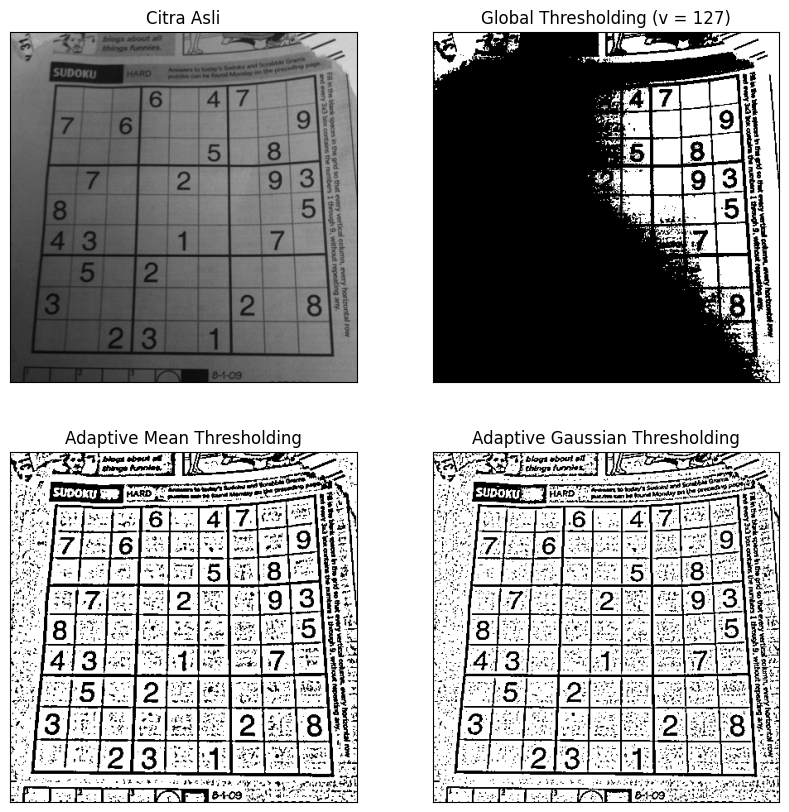

In [65]:
titles = ['Citra Asli',
          'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding',
          'Adaptive Gaussian Thresholding']
hasil = [gray, th_global, th_mean, th_gauss]

plt.figure(figsize=(10, 10))
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(hasil[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()

## 5. Otsu Thresholding manual
### 5a. Membuat lena_gs_lc2.jpg (low contrast) dari lena.jpg

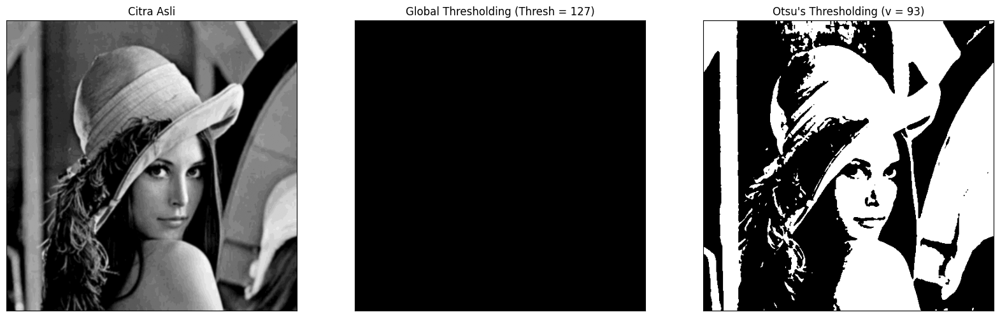

In [66]:
filename = ('/content/drive/MyDrive/PVCK/Images/lena_gs_lc2.jpeg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5,5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh, final_value = -1, -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t]); pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:          # lewati kelas kosong
            continue
        Wb, Wf = pcb * mean_weight, pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2     # between-class variance
        if value > final_value:
            final_thresh, final_value = t, value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

In [67]:
ret2, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Threshold Otsu manual  :", otsu_thresh)
print("Threshold Otsu library :", ret2)

Threshold Otsu manual  : 93
Threshold Otsu library : 92.0


### Pertanyaan: Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitamsemuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

min = 85  max = 108


/tmp/ipykernel_1629/2532992062.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0,256])


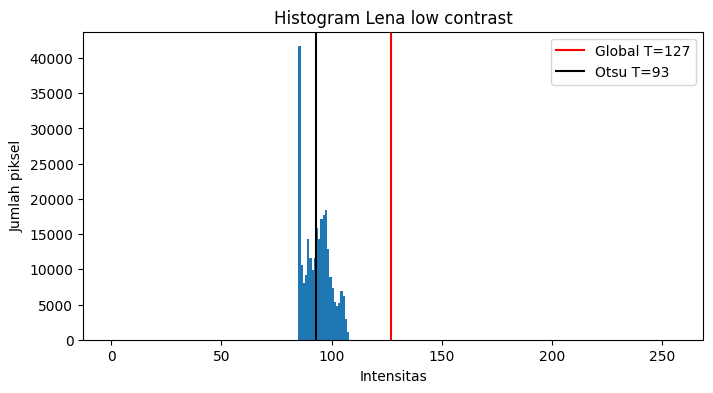

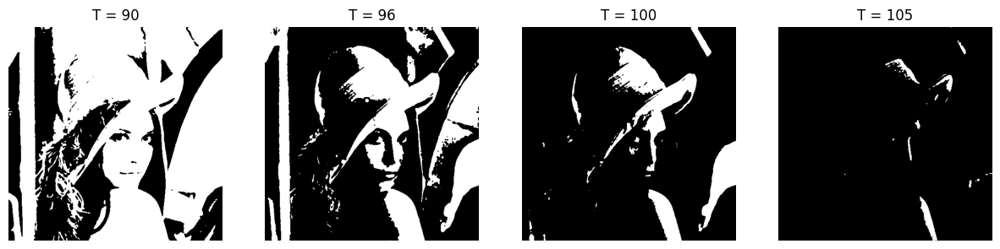

In [68]:
print("min =", blur.min(), " max =", blur.max())

plt.figure(figsize=(8,4))
plt.hist(blur.ravel(), 256, [0,256])
plt.axvline(127, color='red', label='Global T=127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T={otsu_thresh}')
plt.legend(); plt.title('Histogram Lena low contrast')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah piksel'); plt.show()

plt.figure(figsize=(15,4))
for i, t in enumerate([90, 96, 100, 105]):
    _, r = cv.threshold(blur, t, 255, cv.THRESH_BINARY)
    plt.subplot(1,4,i+1); plt.imshow(r,'gray'); plt.title(f'T = {t}'); plt.axis('off')
plt.show()

**Jawaban:** seluruh intensitas Lena low contrast hanya berada di rentang 85–108, sehingga semuanya berada di kiri garis merah T=127. Karena syarat Binary adalah piksel > T menjadi 255, tidak ada piksel yang lolos, jadi seluruh gambar bernilai 0 (hitam). Agar gambar masih terlihat, T harus berada di dalam rentang histogram (sekitar 85–108, misalnya 95–100, mendekati nilai Otsu = 93).

### 5b. Perbandingan dengan KTP Fulan

In [69]:
filename = '/content/drive/MyDrive/PVCK/Images/ktp_fulan.jpg'
ktp = cv.imread(filename)

if ktp is None:
    raise FileNotFoundError(f"File tidak ditemukan: {filename}")

print("Ukuran citra KTP :", ktp.shape)

ktp_gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5,5), 0)

Ukuran citra KTP : (458, 694, 3)


Threshold Otsu KTP : 166


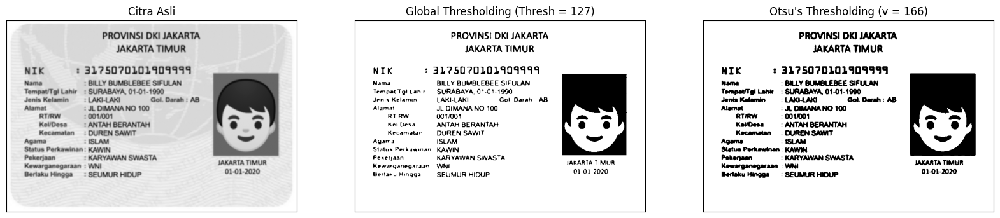

In [70]:
thresh = 127
ret, g127 = cv.threshold(ktp_blur, thresh, 255, cv.THRESH_BINARY)
ktp_otsu, ktp_t = otsu(ktp_blur)

print("Threshold Otsu KTP :", ktp_t)

titles = ['Citra Asli',
          'Global Thresholding (Thresh = ' + str(thresh) + ')',
          "Otsu's Thresholding (v = " + str(ktp_t) + ")"]
citra_ktp = [ktp_blur, g127, ktp_otsu]

plt.figure(figsize=(20,15))
for i in range(len(citra_ktp)):
    plt.subplot(1,3,i+1), plt.imshow(citra_ktp[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 6. Segmentasi Berbasis Region (data.coins)
### 6a. Region growing manual (3 seed x T = 5, 20, 60)

(303, 384)
Seed (baris,kolom): (36, 43) | T=5 | piksel: 18 | intensitas: 158.05555555555554
Seed (baris,kolom): (36, 43) | T=20 | piksel: 956 | intensitas: 162.4100418410042
Seed (baris,kolom): (36, 43) | T=60 | piksel: 85801 | intensitas: 73.96405636297945
Seed (baris,kolom): (5, 5) | T=5 | piksel: 1746 | intensitas: 128.38430698739978
Seed (baris,kolom): (5, 5) | T=20 | piksel: 11723 | intensitas: 113.24149108589951
Seed (baris,kolom): (5, 5) | T=60 | piksel: 85362 | intensitas: 73.31702631147348
Seed (baris,kolom): (36, 39) | T=5 | piksel: 1 | intensitas: 132.0
Seed (baris,kolom): (36, 39) | T=20 | piksel: 50 | intensitas: 136.7
Seed (baris,kolom): (36, 39) | T=60 | piksel: 85748 | intensitas: 73.8432616504175


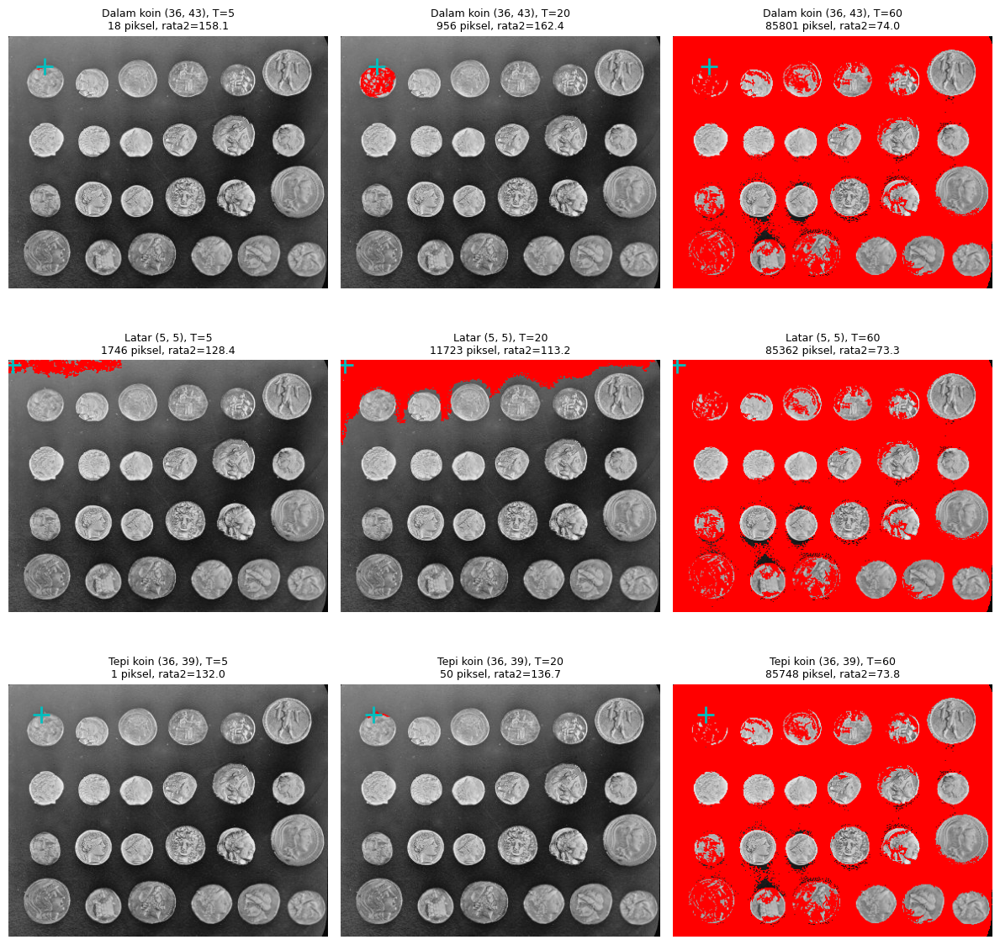

In [71]:
gray_c = data.coins()
print(gray_c.shape)

# Fungsi region growing manual
def region_growing(img, seed, T):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    mask[seed] = True
    queue = deque([seed])
    total, count = float(img[seed]), 1
    while queue:
        r, c = queue.popleft()
        for dr, dc in ((1,0), (-1,0), (0,1), (0,-1)):
            rr, cc = r+dr, c+dc
            if 0 <= rr < h and 0 <= cc < w and not mask[rr, cc]:
                if abs(float(img[rr, cc]) - total/count) <= T:
                    mask[rr, cc] = True
                    queue.append((rr, cc))
                    total += float(img[rr, cc]); count += 1
    return mask, total/count

#Tentukan 3 seed dan nilai T
seeds = [(36, 43), (5, 5), (36, 39)]
names = ['Dalam koin', 'Latar', 'Tepi koin']
Ts    = [5, 20, 60]

#Jalankan dan tampilkan grid 3×3 (seed × T)
base = np.stack([gray_c]*3, axis=-1)        # citra grayscale diubah ke 3 kanal (RGB)

plt.figure(figsize=(12,12))
k = 1
for s, nm in zip(seeds, names):
    for T in Ts:
        m, mu = region_growing(gray_c, s, T)

        overlay = base.copy()
        overlay[m] = [255, 0, 0]            # piksel dalam region diberi warna merah

        plt.subplot(3,3,k); k += 1
        plt.imshow(overlay)
        plt.plot(s[1], s[0], 'c+', markersize=14, markeredgewidth=2)   # tanda seed (cyan)
        plt.title(f'{nm} {s}, T={T}\n{m.sum()} piksel, rata2={mu:.1f}', fontsize=9)
        plt.axis('off')
        print(f"Seed (baris,kolom): {s} | T={T} | piksel: {m.sum()} | intensitas: {mu}")
plt.tight_layout()
plt.show()

### 6b. Dengan skimage.segmentation.flood()

Seed (baris,kolom): (121, 63) | intensitas seed: 224 | piksel region: 177


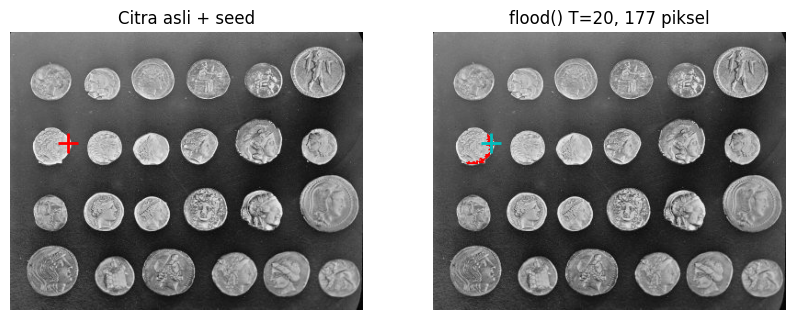

In [72]:
seed = (121, 63)
region = flood(
    gray_c,
    seed_point=seed,
    tolerance=20,
    connectivity=1
)

base = np.stack([gray_c]*3, axis=-1)
overlay = base.copy()
overlay[region] = [255, 0, 0]             # region hasil flood diberi warna merah

print(f"Seed (baris,kolom): {seed} | intensitas seed: {gray_c[seed]} | piksel region: {region.sum()}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(gray_c, 'gray')
plt.plot(seed[1], seed[0], 'r+', markersize=14, markeredgewidth=2)
plt.title('Citra asli + seed'); plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(overlay)
plt.plot(seed[1], seed[0], 'c+', markersize=14, markeredgewidth=2)
plt.title(f'flood() T=20, {region.sum()} piksel'); plt.axis('off')
plt.show()

### 6c. grid 3×3 flood() (seed × T)

Seed (36, 43) | T=5 | piksel: 21
Seed (36, 43) | T=20 | piksel: 919
Seed (36, 43) | T=60 | piksel: 15253
Seed (5, 5) | T=5 | piksel: 280
Seed (5, 5) | T=20 | piksel: 5532
Seed (5, 5) | T=60 | piksel: 39811
Seed (36, 39) | T=5 | piksel: 1
Seed (36, 39) | T=20 | piksel: 27
Seed (36, 39) | T=60 | piksel: 40219


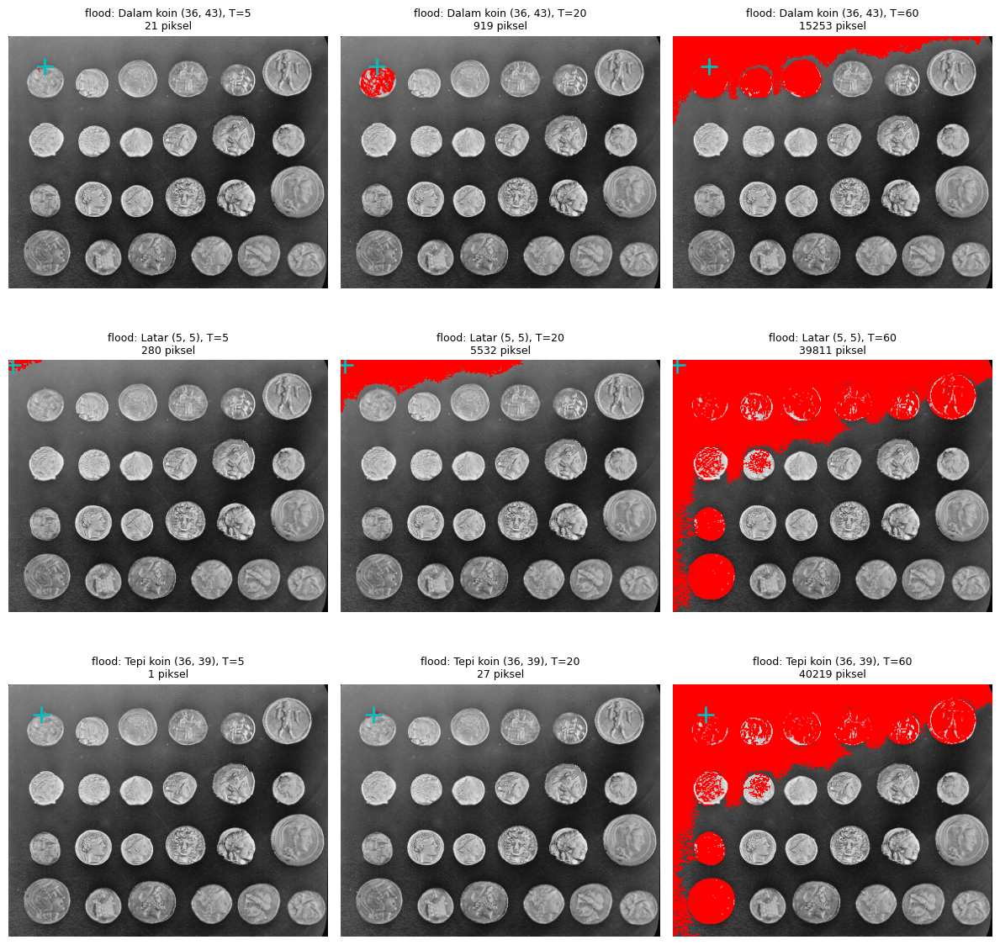

In [73]:
base = np.stack([gray_c]*3, axis=-1)

plt.figure(figsize=(12,12))
k = 1
for s, nm in zip(seeds, names):
    for T in Ts:
        r = flood(gray_c, seed_point=s, tolerance=T, connectivity=1)

        ov = base.copy()
        ov[r] = [255, 0, 0]

        plt.subplot(3,3,k); k += 1
        plt.imshow(ov)
        plt.plot(s[1], s[0], 'c+', markersize=14, markeredgewidth=2)
        plt.title(f'flood: {nm} {s}, T={T}\n{r.sum()} piksel', fontsize=9)
        plt.axis('off')
        print(f"Seed {s} | T={T} | piksel: {r.sum()}")
plt.tight_layout()
plt.show()

## 7. Segmentasi warna: hanya warna biru pada KTP
### 7a. Cara A - Mask biru dengan rentang HSV

Ukuran citra KTP : (458, 694, 3)


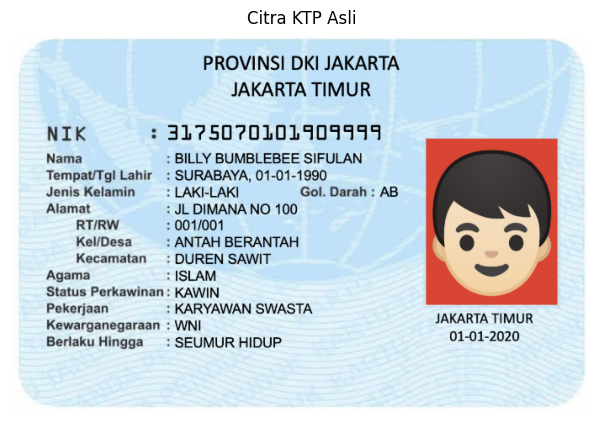

Jumlah piksel biru: 237246 dari 317852


In [74]:
filename = '/content/drive/MyDrive/PVCK/Images/ktp_fulan.jpg'
ktp = cv.imread(filename)

if ktp is None:
    raise FileNotFoundError(f"File tidak ditemukan: {filename}")

print("Ukuran citra KTP :", ktp.shape)

plt.figure(figsize=(8,5))
plt.imshow(cv.cvtColor(ktp, cv.COLOR_BGR2RGB))
plt.title('Citra KTP Asli')
plt.axis('off')
plt.show()


hsv = cv.cvtColor(ktp, cv.COLOR_BGR2HSV)
H, S, V = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]

# rentang biru muda kebiruan pada latar KTP (dari modul)
biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
print("Jumlah piksel biru:", int(biru.sum()), "dari", biru.size)

### 7b. Cara A - tampilkan hanya warna biru

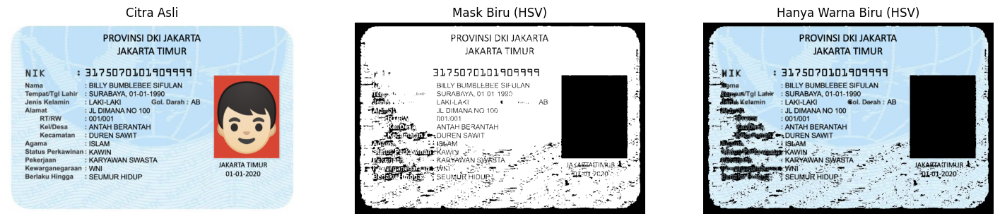

In [75]:
hasil_hsv = np.zeros_like(ktp)          # latar HITAM
hasil_hsv[biru] = ktp[biru]             # hanya piksel biru dipertahankan

plt.figure(figsize=(18,5))
plt.subplot(1,3,1); plt.imshow(cv.cvtColor(ktp, cv.COLOR_BGR2RGB))
plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(biru, 'gray')
plt.title('Mask Biru (HSV)'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(cv.cvtColor(hasil_hsv, cv.COLOR_BGR2RGB))
plt.title('Hanya Warna Biru (HSV)'); plt.axis('off')
plt.show()

### 7c. Cara B – K-Means

In [76]:
from sklearn.cluster import KMeans

rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)
Z = np.float32(rgb.reshape((-1, 3)))

k = 8
rng = np.random.default_rng(42)
sampel = Z[rng.choice(len(Z), size=min(50000, len(Z)), replace=False)]

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(sampel)
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels].reshape(rgb.shape)

print("Pusat cluster (R, G, B):")
print(centers)

Pusat cluster (R, G, B):
[[135 147 155]
 [218 239 248]
 [ 15  16  17]
 [215  70  51]
 [195 224 244]
 [239 210 172]
 [252 254 254]
 [ 59  60  63]]


### 7d. Cara B, ambil cluster yang paling biru dan tampilkan

Cluster biru: [0, 1, 4]
  cluster 0 | warna pusat (RGB): [135 147 155]
  cluster 1 | warna pusat (RGB): [218 239 248]
  cluster 4 | warna pusat (RGB): [195 224 244]


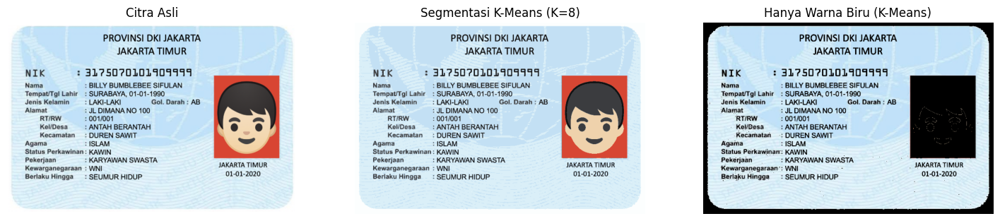

In [77]:
pusat_hsv = cv.cvtColor(centers.reshape(-1,1,3), cv.COLOR_RGB2HSV).reshape(-1,3)
idx_biru = [i for i, (h, s, v) in enumerate(pusat_hsv)
            if 85 <= h <= 130 and s >= 25 and v >= 40]

# cadangan: kalau tidak ada yang memenuhi, ambil cluster dengan komponen B paling dominan
if not idx_biru:
    skor_biru = centers[:,2].astype(int) - (centers[:,0].astype(int) + centers[:,1].astype(int)) / 2
    idx_biru = [int(np.argmax(skor_biru))]

print("Cluster biru:", idx_biru)
for i in idx_biru:
    print(f"  cluster {i} | warna pusat (RGB): {centers[i]}")

mask_km = np.isin(labels, idx_biru).reshape(rgb.shape[:2])
hasil_km = np.zeros_like(rgb)              # latar HITAM
hasil_km[mask_km] = rgb[mask_km]

plt.figure(figsize=(18,5))
plt.subplot(1,3,1); plt.imshow(rgb)
plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(segmented)
plt.title(f'Segmentasi K-Means (K={k})'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(hasil_km)
plt.title('Hanya Warna Biru (K-Means)'); plt.axis('off')
plt.show()

# TUGAS KELOMPOK
## 1. Instal Tesseract + model bahasa Indonesia

In [78]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
ind
osd


## 2. Konfigurasi

In [79]:
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
from difflib import SequenceMatcher
from IPython.display import display

BASE = '/content/drive/MyDrive/PVCK/Images'

# ---- Pengaturan yang SAMA untuk ketiga citra dan semua anggota ----
LANG     = 'ind'   # model bahasa Indonesia
PSM      = 6
CONF_MIN = 60      # kotak hijau hanya untuk kata dengan confidence > 60
LEBAR    = 1600    # semua citra diseragamkan ke lebar 1600 px
AD_BLOCK = 51      # ukuran jendela Adaptive Thresholding (harus ganjil)
AD_C     = 15      # konstanta pengurang Adaptive Thresholding

# ---- Data anggota: file KTP + 10 teks acuan yang terlihat jelas pada KTP-nya ----
ANGGOTA = {
    'Anggota 1': {'file': f'{BASE}/ktp_anggota1.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'KEDIRI', 'PEREMPUAN',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
    'Anggota 2': {'file': f'{BASE}/ktp_anggota2.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'LUMAJANG', 'LAKI-LAKI',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
    'Anggota 3': {'file': f'{BASE}/ktp_anggota3.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'BLITAR', 'LAKI-LAKI',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
}

METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']
KOLOM  = {'Berwarna asli': 'OCR citra berwarna',
          'Segmentasi Otsu': 'OCR Otsu',
          'Segmentasi Adaptive': 'OCR Adaptive'}

## 3. Fungsi-fungsi

In [80]:
import os

def muat_citra(path):
    if not os.path.exists(path):
        folder = os.path.dirname(path)
        isi = os.listdir(folder) if os.path.exists(folder) else 'folder tidak ada'
        raise FileNotFoundError(f'File tidak ditemukan: {path}\nIsi folder: {isi}')
    img = cv.imread(path)
    if img is None:
        raise ValueError(f'cv.imread gagal membaca: {path}')
    return img

def siapkan_tiga_citra(path):
    """Satu citra KTP -> tiga versi dengan ukuran sama: berwarna, Otsu, Adaptive."""
    bgr = muat_citra(path)
    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)), interpolation=cv.INTER_CUBIC)

    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)                       # grayscale dulu
    _, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, AD_BLOCK, AD_C)
    return {'Berwarna asli': bgr, 'Segmentasi Otsu': otsu, 'Segmentasi Adaptive': adaptive}

def jalankan_ocr(img):
    """image_to_string + image_to_data dengan bahasa dan --psm yang sama."""
    img_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    cfg = f'--oem 3 --psm {PSM}'
    teks = pytesseract.image_to_string(img_ocr, lang=LANG, config=cfg)
    data = pytesseract.image_to_data(img_ocr, lang=LANG, config=cfg, output_type=Output.DICT)
    return teks, data

def rata_conf(data):
    """Rata-rata confidence seluruh kata yang dikenali (confidence >= 0 dan teks tidak kosong)."""
    c = [float(cf) for cf, t in zip(data['conf'], data['text']) if t.strip() and float(cf) >= 0]
    return float(np.mean(c)) if c else 0.0

def gambar_kotak(img, data):
    """Kotak hijau pada kata dengan confidence > CONF_MIN (hanya token yang memuat huruf/angka)."""
    kanvas = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    n = 0
    for i, t in enumerate(data['text']):
        if t.strip() and any(ch.isalnum() for ch in t) and float(data['conf'][i]) > CONF_MIN:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n += 1
    return kanvas, n

def _bersih(t):
    return t.strip(':;,.|_\'"`[]() \t')

def baca_item(item, teks):
    """Cari bagian teks OCR yang paling mirip dengan item acuan.
    Return (teks yang terbaca, cocok?). Cocok = semua huruf/angka sama persis,
    huruf besar-kecil dan spasi di awal/akhir diabaikan."""
    tok = [_bersih(t) for t in teks.split() if _bersih(t)]
    n, target = len(item.split()), item.upper()
    terbaik, skor = '', 0.0
    for k in range(max(1, n - 1), n + 3):
        for i in range(len(tok) - k + 1):
            cand = ' '.join(tok[i:i + k]).upper()
            s = SequenceMatcher(None, cand, target).ratio()
            if s > skor:
                terbaik, skor = cand, s
    if skor == 1.0:
        return item, True
    if skor >= 0.5:
        return terbaik, False
    return '(tidak terbaca)', False

def jenis_salah(item, baca):
    if baca == '(tidak terbaca)':
        return 'teks tidak terbaca'
    a, b = item.upper(), baca.upper()
    if a in b:
        return 'kata menyatu dengan teks lain di sekitarnya'
    if len(a) == len(b):
        beda = [f'{x}->{y}' for x, y in zip(a, b) if x != y]
        return 'huruf tertukar (' + ', '.join(beda) + ')'
    return 'huruf hilang' if len(b) < len(a) else 'huruf tambahan/salah baca'

## 4. Jalankan OCR untuk semua anggota

Anggota 1 selesai | ukuran citra: (991, 1600)
Anggota 2 selesai | ukuran citra: (1008, 1600)
Anggota 3 selesai | ukuran citra: (1017, 1600)
Tiga citra untuk dibandingkan: Anggota 1


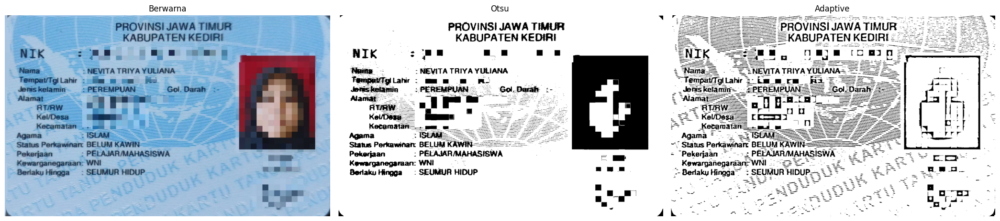

Tiga citra untuk dibandingkan: Anggota 2


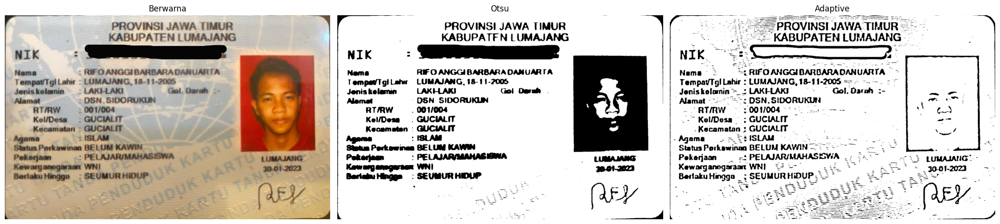

Tiga citra untuk dibandingkan: Anggota 3


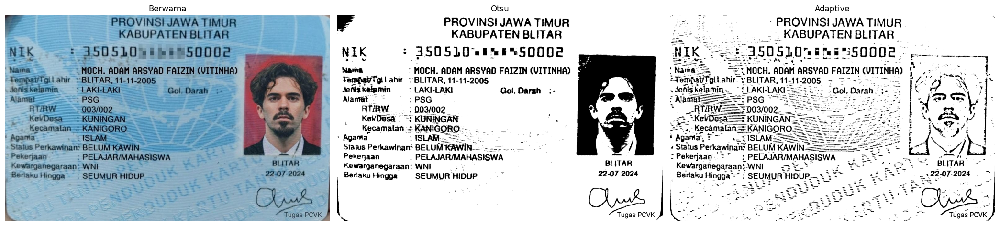

In [81]:
HASIL = {}
for nama, info in ANGGOTA.items():
    citra = siapkan_tiga_citra(info['file'])
    HASIL[nama] = {}
    for m in METODE:
        teks, data = jalankan_ocr(citra[m])
        kotak, n_kotak = gambar_kotak(citra[m], data)
        baca = [baca_item(it, teks) for it in info['acuan']]
        HASIL[nama][m] = {'teks': teks, 'data': data, 'kotak': kotak, 'n_kotak': n_kotak,
                          'baca': [b for b, _ in baca], 'cocok': [c for _, c in baca],
                          'conf': rata_conf(data)}
    print(nama, 'selesai | ukuran citra:', citra['Berwarna asli'].shape[:2])


LABEL = {'Berwarna asli': 'Berwarna', 'Segmentasi Otsu': 'Otsu', 'Segmentasi Adaptive': 'Adaptive'}

for nama, info in ANGGOTA.items():
    citra = siapkan_tiga_citra(info['file'])
    print(f'Tiga citra untuk dibandingkan: {nama}')
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        img = citra[m]
        if img.ndim == 3:
            a.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        else:
            a.imshow(img, cmap='gray', vmin=0, vmax=255)
        a.set_title(LABEL[m])
        a.axis('off')
    plt.tight_layout()
    plt.show()

## 5. Tampilkan kotak hijau

Hasil Pembacaan Teks: Anggota 1


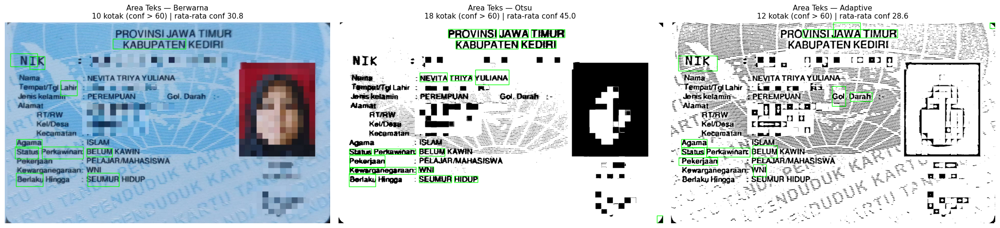

Hasil Pembacaan Teks: Anggota 2


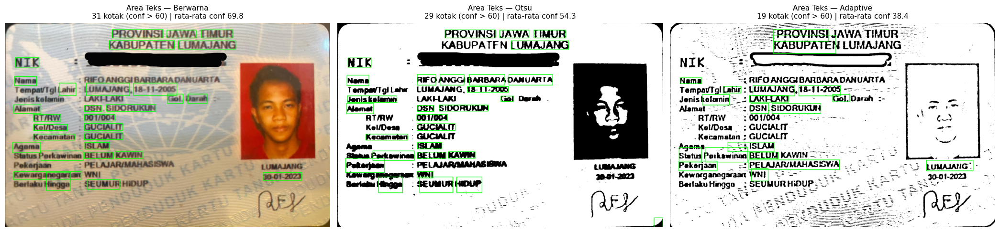

Hasil Pembacaan Teks: Anggota 3


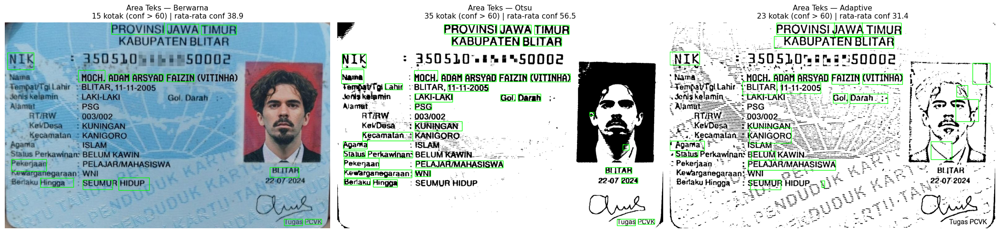

In [82]:
for nama in ANGGOTA:
    print(f'Hasil Pembacaan Teks: {nama}')
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        h = HASIL[nama][m]
        a.imshow(cv.cvtColor(h['kotak'], cv.COLOR_BGR2RGB))
        a.set_title(f"Area Teks — {LABEL[m]}\n{h['n_kotak']} kotak (conf > {CONF_MIN}) | rata-rata conf {h['conf']:.1f}", fontsize=11)
        a.axis('off')
    plt.tight_layout()
    plt.show()

In [83]:
for nama in ANGGOTA:
    print(f'\n######## {nama} ########')
    for m in METODE:
        print(f'========== {LABEL[m].upper()} ==========')
        teks = '\n'.join(l for l in HASIL[nama][m]['teks'].splitlines() if l.strip())
        print(teks)
        print()


######## Anggota 1 ########
========== BERWARNA ==========
| Lean —— — 25. AA z mw fiko Pa Pee
TT LL — FA. KA ET TT ——— N
5 5 — PROVINSIJAWATIMUR ————————
TE “KABUPATEN KEDIRE
—  —— SE AA
NK “— uu LN  —-“ ——
— IK — la Le Pel m0 a IE -
Ba AA 2 ng 2
- Nama :NEVITATRIYAYULANA-————— — 5
— TempatTgi Lahir sala mw Ka 2 — 22 —
5 5 K———— Sa ae ———
2. ——— Ba —-—-——-
— RERW  — A—
. S5 3 Kel/Desa— PA :
ne ———
Agama 5 SEE
— Status Perkawinan BELUM KAWIN-—-—-—-————- - -
Pekerjaan —— : PEKAJAR/MAHASISWA ”—- —-————— — |
ea AA "2
Berlaku Hingga” : SEUMUR HIDUP—- --——. — NN
FA — AA - — Ta AA H3 — 2 -
- PA 5 — aan
: ag
- : ”

========== OTSU ==========
— -
PROVINSI JAWA TIMUR
| KABUPATEN KEDIRI
NIK oo : ”x ". " »
Mes. - MEVITA TRIYA YULIANA
IR NI MN
Ketamatan mmm... SE -
Status Perkawinan BELUM KAWIN — ——-—---—“
Pekerjaan : PELAJAR MAHASISWA Ta FE
Kewarganegaraan: WNI Haa EF
Berlaku Hingga: SEUMUR HIDUP 1...
-
ag 23 N
-
bo - y

========== ADAPTIVE ==========
3 Eee" SROVINSI JAWA FS 3 TEE TES ON
(si BB 

## 6. Tabel perbandingan 10 item

In [84]:
for nama, info in ANGGOTA.items():
    tabel = pd.DataFrame({'No.': range(1, len(info['acuan']) + 1),
                          'Teks sebenarnya': info['acuan']})
    gaya = pd.DataFrame('', index=range(len(info['acuan'])), columns=['Teks sebenarnya'] + list(KOLOM.values()))
    for m, kol in KOLOM.items():
        tabel[kol] = HASIL[nama][m]['baca']
        gaya[kol] = ['background-color:#c8f7c5' if ok else 'background-color:#f7c5c5'
                     for ok in HASIL[nama][m]['cocok']]
    tabel = tabel.set_index('No.')
    gaya.index = tabel.index
    print(f'=== Tabel perbandingan {nama} (hijau = cocok, merah = tidak cocok) ===')
    display(tabel.style.apply(lambda _: gaya, axis=None))

=== Tabel perbandingan Anggota 1 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,PROVINSIJAWATIMUR,PROVINSI,SROVINSI
2,JAWA TIMUR,PROVINSIJAWATIMUR,JAWA TIMUR,PROVINSIJAWATIMUR
3,KABUPATEN,“KABUPATEN,KABUPATEN,KABUPATEN
4,KEDIRI,KEDIRE,KEDIRI,KEDIRIS
5,PEREMPUAN,PEKERJAAN,PEKERJAAN,“PEREMPUANC
6,ISLAM,SALA,(tidak terbaca),SAM
7,BELUM KAWIN,BELUM KAWIN-—-—-—-————-,BELUM KAWIN,BELUM KAWIN
8,PELAJAR/MAHASISWA,PEKAJAR/MAHASISWA,PELAJAR MAHASISWA,PEKAYAR/MAHASISWA
9,WNI,N,WNI,WNI


=== Tabel perbandingan Anggota 2 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
2,JAWA TIMUR,JAWA HMUR,JAWA TIMUR,JAWATIMUR
3,KABUPATEN,KABUPATEN,KABUPATEN,KABUPATEN
4,LUMAJANG,LUMAJANG,LUMAJANG,LUMAJANG
5,LAKI-LAKI,LAKI-LAKI,LAKIHLAKI,(tidak terbaca)
6,ISLAM,ISLAM,ISLAM,TEISLAM
7,BELUM KAWIN,BELUM KAWIN,BELUM KAWIN,BELUM KAYAN
8,PELAJAR/MAHASISWA,AGAMA ISLAM,PELAJAR/MAHASISWA,PELAJAR/MAHASISYIA
9,WNI,WNI!,WNI,WNI


=== Tabel perbandingan Anggota 3 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
2,JAWA TIMUR,JAWA TIMUR,JAWA TIMUR,JAWA TIMUR
3,KABUPATEN,KABUPATENBLITAR,KABUPATEN,KABUPATENBLITAR
4,BLITAR,BLITAR,BLITAR,BLITAR
5,LAKI-LAKI,-LAKELAKI,LAKI-LAKI,“LAKI-LAKI
6,ISLAM,JENISKELAMIN,ISLAM“,ISLAM
7,BELUM KAWIN,(tidak terbaca),BELUMKAWIN,BELUM KAWIN
8,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA
9,WNI,WNI,WNI,WNI”


## 7. Ringkasan kecocokan dan confidence

In [85]:
baris_gabungan = []
for nama, info in ANGGOTA.items():
    total = len(info['acuan'])
    baris = []
    for m in METODE:
        h = HASIL[nama][m]
        tepat = sum(h['cocok'])
        baris.append({'Citra masukan OCR': m,
                      'Item terbaca tepat': f'{tepat} dari {total}',
                      'Kecocokan (%)': round(100 * tepat / total, 1),
                      'Rata-rata confidence': round(h['conf'], 1),
                      'Kotak hijau (conf > 60)': h['n_kotak']})
    print(f'=== Ringkasan {nama} ===')
    display(pd.DataFrame(baris).set_index('Citra masukan OCR'))

for m in METODE:
    tepat = sum(sum(HASIL[n][m]['cocok']) for n in ANGGOTA)
    total = sum(len(ANGGOTA[n]['acuan']) for n in ANGGOTA)
    conf = np.mean([HASIL[n][m]['conf'] for n in ANGGOTA])
    baris_gabungan.append({'Citra masukan OCR': m,
                           'Item terbaca tepat': f'{tepat} dari {total}',
                           'Kecocokan (%)': round(100 * tepat / total, 1),
                           'Rata-rata confidence': round(float(conf), 1)})
GAB = pd.DataFrame(baris_gabungan).set_index('Citra masukan OCR')
print('=== Ringkasan GABUNGAN seluruh anggota ===')
display(GAB)

=== Ringkasan Anggota 1 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,0 dari 10,0.0,30.8,10
Segmentasi Otsu,7 dari 10,70.0,45.0,18
Segmentasi Adaptive,3 dari 10,30.0,28.6,12


=== Ringkasan Anggota 2 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,7 dari 10,70.0,69.8,31
Segmentasi Otsu,9 dari 10,90.0,54.3,29
Segmentasi Adaptive,4 dari 10,40.0,38.4,19


=== Ringkasan Anggota 3 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,6 dari 10,60.0,38.9,15
Segmentasi Otsu,7 dari 10,70.0,56.5,35
Segmentasi Adaptive,6 dari 10,60.0,31.4,23


=== Ringkasan GABUNGAN seluruh anggota ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Citra masukan OCR,,,
Berwarna asli,13 dari 30,43.3,46.5
Segmentasi Otsu,23 dari 30,76.7,51.9
Segmentasi Adaptive,13 dari 30,43.3,32.8


## 1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
### jawab:
Citra hasil **segmentasi Otsu** menghasilkan pembacaan paling tepat, yaitu 23 dari 30 item (76,7%) dengan rata-rata confidence 51,9. Sebagai pembanding, citra berwarna asli terbaca 13 dari 30 item (43,3%, confidence 46,5) dan segmentasi Adaptive 13 dari 30 item (43,3%, confidence 32,8). Otsu juga tertinggi pada setiap KTP: Anggota 1 (7 dari 10), Anggota 2 (9 dari 10), dan Anggota 3 (7 dari 10), sedangkan citra berwarna hanya 0, 7, dan 6 dari 10.

## 2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
### jawab:
- **Huruf tertukar:** pada Anggota 1 (citra berwarna), "KEDIRI" terbaca "KEDIRE" (huruf I terbaca E).
- **Kata menyatu dan spasi hilang:** pada Anggota 1 (citra berwarna), "PROVINSI" dan "JAWA TIMUR" terbaca sebagai satu kata "PROVINSIJAWATIMUR", sehingga kedua item dihitung tidak cocok.
- **Simbol tambahan:** pada Anggota 1 (citra berwarna), "KABUPATEN" terbaca "“KABUPATEN" dengan tanda kutip di depannya.
- **Teks tidak terbaca:** pada Anggota 1 (Otsu), "ISLAM" tidak terbaca, dan pada Anggota 2 (Adaptive), "LAKI-LAKI" tidak terbaca.
- **Item gagal dibaca:** pada Anggota 1 (citra berwarna), "PEREMPUAN" hanya terbaca "PEKERJAAN", yaitu label lain pada KTP. Ini bukan salah huruf, melainkan item acuan yang tidak berhasil dibaca.

## 3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
### jawab:
- Segmentasi Otsu: naik di 3 citra, turun di 0, sama di 0 (dari 3 KTP)
- Segmentasi Adaptive: naik di 1 citra, turun di 1, sama di 1 (dari 3 KTP)

**Tidak selalu.** Otsu meningkatkan kecocokan pada ketiga KTP (Anggota 1: 0 menjadi 7 item, Anggota 2: 7 menjadi 9, Anggota 3: 6 menjadi 7). Adaptive tidak konsisten: naik pada Anggota 1 (0 menjadi 3), turun pada Anggota 2 (7 menjadi 4), dan sama pada Anggota 3 (6 dan 6). Secara gabungan Adaptive sama dengan citra berwarna (13 dari 30) tetapi dengan confidence lebih rendah, sehingga segmentasi hanya membantu bila metodenya cocok dengan kondisi foto.

## 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
### jawab:
Latar KTP berwarna biru muda dengan pola peta, garis halus, dan watermark "KARTU TANDA PENDUDUK" yang nilai keabuannya dekat dengan teks. Pada citra berwarna, pola ini bersaing dengan huruf: kecocokan citra berwarna hanya 43,3% dengan rata-rata confidence 46,5. Hasilnya paling buruk pada KTP Anggota 1 yang berlatar biru muda bermotif garis halus (0 dari 10 item, confidence 30,8), sedangkan KTP Anggota 2 tampak berlatar lebih terang dengan pola yang lebih samar dan terbaca jauh lebih baik pada citra berwarna (7 dari 10 item, confidence 69,8). Otsu memakai satu ambang global sehingga latar yang terang berubah menjadi putih dan teks yang gelap menjadi hitam, sehingga sebagian besar pola latar hilang. Kecocokan naik menjadi 76,7% (confidence 51,9) dan naik pada ketiga KTP. Adaptive menghitung ambang per jendela kecil sehingga variasi lokal pada garis halus dan watermark ikut menjadi goresan hitam. Kecocokannya hanya 43,3%, tidak lebih baik dari citra berwarna, dan rata-rata confidence-nya paling rendah (32,8), terendah di ketiga KTP. Jumlah kotak hijau Adaptive tidak lebih banyak dari Otsu (rata-rata 18,0 dibanding 27,3), tetapi confidence-nya rendah, artinya Tesseract kurang yakin pada tulisan yang bercampur dengan goresan latar. Selain pola latar, ketajaman dan pencahayaan foto tiap KTP juga ikut memengaruhi hasil. Kesimpulannya, warna dan pola latar yang rapat menurunkan keterbacaan teks. Pemisahan latar dengan ambang global (Otsu) paling efektif pada ketiga KTP ini, sedangkan ambang lokal yang kecil justru ikut memperkuat pola latar.

## 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
### jawab:
**Ya**, secara gabungan. Segmentasi Otsu memiliki rata-rata confidence tertinggi (51,9) sekaligus kecocokan tertinggi (76,7%). Namun per KTP hal ini tidak selalu berlaku: pada Anggota 2, citra berwarna punya confidence lebih tinggi (69,8) daripada Otsu (54,3), tetapi kecocokannya lebih rendah (70% dibanding 90%). Jadi confidence hanya menunjukkan keyakinan mesin pada kata yang dikenalinya, bukan jaminan bahwa kata acuan terbaca tepat.